In [1]:

# CELL 1 — Environment, reproducibility and output folders

import os
import re
import json
import time
import random
import zipfile
import warnings
import platform
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

INPUT_DIR = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working")
RESULTS_DIR = OUTPUT_DIR / "fgai_results"
MODELS_DIR = OUTPUT_DIR / "fgai_models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

DATASET_URL = (
    "https://www.kaggle.com/datasets/"
    "kingburrito666/shakespeare-plays"
)

print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

files = [p for p in INPUT_DIR.rglob("*") if p.is_file()]
print("\nAttached files:")
for p in files:
    print(f"{p} ({p.stat().st_size / 1024:.1f} KB)")

if not files:
    raise FileNotFoundError(
        "No dataset is attached. Add the Shakespeare Plays dataset "
        "using Kaggle's Add Input option."
    )


Python: 3.13.15
TensorFlow: 2.20.0
NumPy: 2.1.3
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Attached files:
/kaggle/input/datasets/kingburrito666/shakespeare-plays/alllines.txt (4476.4 KB)
/kaggle/input/datasets/kingburrito666/shakespeare-plays/Shakespeare_data.csv (9950.1 KB)
/kaggle/input/datasets/kingburrito666/shakespeare-plays/william-shakespeare-black-silhouette.jpg (25.7 KB)


In [2]:

# CELL 2 — Load Shakespeare dialogue

csv_candidates = list(INPUT_DIR.rglob("Shakespeare_data.csv"))

if not csv_candidates:
    raise FileNotFoundError(
        "Shakespeare_data.csv was not found. Check that the "
        "Shakespeare Plays dataset is attached."
    )

csv_path = csv_candidates[0]
df = pd.read_csv(csv_path, low_memory=False)

required_column = "PlayerLine"
if required_column not in df.columns:
    raise ValueError(
        f"Missing {required_column}. Available columns: "
        f"{df.columns.tolist()}"
    )

lines = df[required_column].dropna().astype(str)
lines = lines[lines.str.strip().ne("")]

raw_text = "\n".join(lines.tolist())

if len(raw_text) < 100_000:
    raise ValueError(
        "The extracted corpus is unexpectedly small. Inspect the dataset."
    )

print("Dataset file:", csv_path.name)
print("Dataset rows:", len(df))
print("Non-empty dialogue lines:", len(lines))
print("Characters:", f"{len(raw_text):,}")
print("\nText preview:\n")
print(raw_text[:2000])

dataset_info = {
    "dataset_name": "Shakespeare Plays",
    "source_url": DATASET_URL,
    "source_file": csv_path.name,
    "source_column": required_column,
    "csv_rows": int(len(df)),
    "nonempty_dialogue_lines": int(len(lines)),
    "character_count": len(raw_text)
}


Dataset file: Shakespeare_data.csv
Dataset rows: 111396
Non-empty dialogue lines: 111396
Characters: 4,366,287

Text preview:

ACT I
SCENE I. London. The palace.
Enter KING HENRY, LORD JOHN OF LANCASTER, the EARL of WESTMORELAND, SIR WALTER BLUNT, and others
So shaken as we are, so wan with care,
Find we a time for frighted peace to pant,
And breathe short-winded accents of new broils
To be commenced in strands afar remote.
No more the thirsty entrance of this soil
Shall daub her lips with her own children's blood,
Nor more shall trenching war channel her fields,
Nor bruise her flowerets with the armed hoofs
Of hostile paces: those opposed eyes,
Which, like the meteors of a troubled heaven,
All of one nature, of one substance bred,
Did lately meet in the intestine shock
And furious close of civil butchery
Shall now, in mutual well-beseeming ranks,
March all one way and be no more opposed
Against acquaintance, kindred and allies:
The edge of war, like an ill-sheathed knife,
No more shal

In [3]:

# CELL 3 — Preprocess and create next-word prediction examples

CONTEXT_LEN = 24
MAX_VOCAB = 10000

# Maximum number of examples per partition.
TRAIN_EXAMPLES = 50000
EVAL_EXAMPLES = 10000
WINDOW_STRIDE = 2

def tokenize_text(text):
    return re.findall(
        r"[a-zA-Z]+(?:'[a-zA-Z]+)?|[0-9]+|[^\w\s]",
        text.lower()
    )

tokens = tokenize_text(raw_text)

if len(tokens) < 10000:
    raise ValueError("Too few tokens extracted from the dataset.")

n_tokens = len(tokens)
train_end = int(n_tokens * 0.80)
val_end = int(n_tokens * 0.90)

train_tokens = tokens[:train_end]
val_tokens = tokens[train_end:val_end]
test_tokens = tokens[val_end:]

# Vocabulary built from training tokens only.
counts = Counter(train_tokens)
vocab_words = ["<PAD>", "<UNK>"] + [
    word for word, _ in counts.most_common(MAX_VOCAB - 2)
]

word_to_id = {word: i for i, word in enumerate(vocab_words)}
id_to_word = {i: word for word, i in word_to_id.items()}

VOCAB_SIZE = len(vocab_words)
PAD_ID = word_to_id["<PAD>"]
UNK_ID = word_to_id["<UNK>"]

def encode_tokens(items):
    return np.asarray(
        [word_to_id.get(word, UNK_ID) for word in items],
        dtype=np.int32
    )

train_ids = encode_tokens(train_tokens)
val_ids = encode_tokens(val_tokens)
test_ids = encode_tokens(test_tokens)

def make_examples(ids, max_examples, stride=WINDOW_STRIDE):
    width = CONTEXT_LEN + 1

    if len(ids) < width:
        raise ValueError("Partition is shorter than the context window.")

    windows = np.lib.stride_tricks.sliding_window_view(
        ids, width
    )[::stride]

    if len(windows) > max_examples:
        # Sample evenly across the full partition.
        indices = np.linspace(
            0, len(windows) - 1, max_examples, dtype=np.int64
        )
        windows = windows[indices]

    windows = np.asarray(windows, dtype=np.int32).copy()
    return windows[:, :-1], windows[:, -1]

X_train, y_train = make_examples(train_ids, TRAIN_EXAMPLES)
X_val, y_val = make_examples(val_ids, EVAL_EXAMPLES)
X_test, y_test = make_examples(test_ids, EVAL_EXAMPLES)

print("Total tokens:", f"{n_tokens:,}")
print("Training / validation / test token counts:",
      len(train_ids), len(val_ids), len(test_ids))
print("Vocabulary size:", VOCAB_SIZE)
print("Training examples:", X_train.shape, y_train.shape)
print("Validation examples:", X_val.shape, y_val.shape)
print("Test examples:", X_test.shape, y_test.shape)

print("\nExample context:")
print(" ".join(id_to_word[int(i)] for i in X_train[0]))
print("Next-word target:", id_to_word[int(y_train[0])])

dataset_info.update({
    "token_count": int(n_tokens),
    "context_length": CONTEXT_LEN,
    "vocabulary_size": VOCAB_SIZE,
    "train_examples": int(len(X_train)),
    "validation_examples": int(len(X_val)),
    "test_examples": int(len(X_test)),
    "split": "80% train / 10% validation / 10% test, chronological"
})

with open(RESULTS_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(dataset_info, f, indent=2)

with open(RESULTS_DIR / "vocabulary.json", "w", encoding="utf-8") as f:
    json.dump(vocab_words, f)


Total tokens: 1,002,945
Training / validation / test token counts: 802356 100294 100295
Vocabulary size: 10000
Training examples: (50000, 24) (50000,)
Validation examples: (10000, 24) (10000,)
Test examples: (10000, 24) (10000,)

Example context:
act i scene i . london . the palace . enter king henry , lord john of lancaster , the earl of westmoreland ,
Next-word target: sir


In [4]:

# CELL 4 — Build Simple RNN, Bidirectional RNN, LSTM and GRU

EMBED_DIM = 64
HIDDEN_UNITS = 96
DENSE_UNITS = 128
BATCH_SIZE = 256
EPOCHS = 10
LEARNING_RATE = 0.001

MODEL_NAMES = [
    "SimpleRNN",
    "BidirectionalRNN",
    "LSTM",
    "GRU"
]

def build_model(model_name):
    inputs = tf.keras.Input(
        shape=(CONTEXT_LEN,), dtype=tf.int32, name="context"
    )

    x = tf.keras.layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBED_DIM,
        name="embedding"
    )(inputs)

    if model_name == "SimpleRNN":
        x = tf.keras.layers.SimpleRNN(
            HIDDEN_UNITS, name="simple_rnn"
        )(x)

    elif model_name == "BidirectionalRNN":
        x = tf.keras.layers.Bidirectional(
            tf.keras.layers.SimpleRNN(HIDDEN_UNITS),
            name="bidirectional_rnn"
        )(x)

    elif model_name == "LSTM":
        x = tf.keras.layers.LSTM(
            HIDDEN_UNITS, name="lstm"
        )(x)

    elif model_name == "GRU":
        x = tf.keras.layers.GRU(
            HIDDEN_UNITS, name="gru"
        )(x)

    else:
        raise ValueError(f"Unknown model: {model_name}")

    x = tf.keras.layers.Dense(
        DENSE_UNITS, activation="relu", name="dense_hidden"
    )(x)

    outputs = tf.keras.layers.Dense(
        VOCAB_SIZE, activation="softmax", name="next_word"
    )(x)

    model = tf.keras.Model(inputs, outputs, name=model_name)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="sparse_categorical_crossentropy",
        metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="accuracy"
            )
        ]
    )

    return model

preview = build_model("SimpleRNN")
preview.summary()
print("\nConfiguration:", {
    "context_length": CONTEXT_LEN,
    "vocabulary_size": VOCAB_SIZE,
    "embedding_dimension": EMBED_DIM,
    "hidden_units": HIDDEN_UNITS,
    "batch_size": BATCH_SIZE,
    "maximum_epochs": EPOCHS,
    "learning_rate": LEARNING_RATE
})
del preview


I0000 00:00:1792048032.356154      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792048032.359737      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ context (InputLayer)            │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 24, 64)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 96)             │        15,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 128)            │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ next_word (Dense)               │ (None, 10000)          │     1,290,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,957,872 (7.47 MB)

 Trainable params: 1,957,872 (7.47 MB)

 Non-trainable params: 0 (0.00 B)


Configuration: {'context_length': 24, 'vocabulary_size': 10000, 'embedding_dimension': 64, 'hidden_units': 96, 'batch_size': 256, 'maximum_epochs': 10, 'learning_rate': 0.001}


In [5]:

# CELL 5 — Train and evaluate all four models

models = {}
histories = {}
result_rows = []

for model_index, model_name in enumerate(MODEL_NAMES):
    print("\n" + "=" * 80)
    print(f"MODEL {model_index + 1}/{len(MODEL_NAMES)}: {model_name}")
    print("=" * 80)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_model(model_name)
    checkpoint_path = MODELS_DIR / f"{model_name}_best.keras"

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=0
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=3,
            restore_best_weights=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.5,
            patience=1,
            min_lr=1e-5,
            verbose=1
        )
    ]

    start_time = time.perf_counter()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=callbacks,
        verbose=1
    )

    training_seconds = time.perf_counter() - start_time

    # Load the best validation-loss checkpoint for evaluation.
    model = tf.keras.models.load_model(checkpoint_path)

    val_loss, val_accuracy = model.evaluate(
        X_val, y_val, batch_size=BATCH_SIZE, verbose=0
    )
    test_loss, test_accuracy = model.evaluate(
        X_test, y_test, batch_size=BATCH_SIZE, verbose=0
    )

    # Perplexity = exp(mean cross-entropy); cap protects against overflow.
    val_perplexity = float(np.exp(min(float(val_loss), 50)))
    test_perplexity = float(np.exp(min(float(test_loss), 50)))

    models[model_name] = model
    histories[model_name] = history.history

    history_df = pd.DataFrame(history.history)
    history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
    history_df.to_csv(
        RESULTS_DIR / f"{model_name}_training_history.csv",
        index=False
    )

    result_rows.append({
        "Model": model_name,
        "Parameters": int(model.count_params()),
        "Best_Epoch": int(np.argmin(history.history["val_loss"]) + 1),
        "Epochs_Trained": len(history.history["loss"]),
        "Training_Time_Seconds": round(training_seconds, 2),
        "Validation_Loss": float(val_loss),
        "Validation_Accuracy": float(val_accuracy),
        "Validation_Perplexity": val_perplexity,
        "Test_Loss": float(test_loss),
        "Test_Accuracy": float(test_accuracy),
        "Test_Perplexity": test_perplexity
    })

    print(f"\n{model_name} results")
    print(f"Training time: {training_seconds:.2f} seconds")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print(f"Test loss: {test_loss:.4f}")
    print(f"Test accuracy: {test_accuracy:.4f}")
    print(f"Test perplexity: {test_perplexity:.2f}")

results_df = pd.DataFrame(result_rows)
results_df = results_df.sort_values(
    "Validation_Loss", ascending=True
).reset_index(drop=True)

results_df.to_csv(
    RESULTS_DIR / "model_comparison.csv", index=False
)

print("\nFINAL COMPARISON — sorted by validation loss")
display(results_df)



MODEL 1/4: SimpleRNN
Epoch 1/10
 34/196 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0492 - loss: 8.5635  

I0000 00:00:1792048045.202989     139 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


196/196 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.0920 - loss: 6.5112 - val_accuracy: 0.1024 - val_loss: 6.0348 - learning_rate: 0.0010
Epoch 2/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.1015 - loss: 5.9185 - val_accuracy: 0.1243 - val_loss: 5.9554 - learning_rate: 0.0010
Epoch 3/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.1173 - loss: 5.7046 - val_accuracy: 0.1273 - val_loss: 5.9093 - learning_rate: 0.0010
Epoch 4/10
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.1234 - loss: 5.5062 - val_accuracy: 0.1273 - val_loss: 5.9082 - learning_rate: 0.0010
Epoch 5/10
190/196 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1296 - loss: 5.3647
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.1300 - loss: 5.3302 - val_accuracy: 0.1260 - val_loss: 5.9574 - learning_rate: 0.0010
Epoch 6/10
189/196 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1372 - loss: 5.1848
Epoch 6: Redu

,Model,Parameters,Best_Epoch,Epochs_Trained,Training_Time_Seconds,Validation_Loss,Validation_Accuracy,Validation_Perplexity,Test_Loss,Test_Accuracy,Test_Perplexity
0,GRU,1989072,3,6,14.84,5.874403,0.1288,355.812177,5.729193,0.1230,307.720756
1,LSTM,2004240,4,7,20.16,5.895957,0.1304,363.564598,5.739556,0.1267,310.926426
2,SimpleRNN,1957872,4,7,14.40,5.908167,0.1273,368.031069,5.728740,0.1228,307.581538
3,BidirectionalRNN,1985616,3,6,15.70,6.011996,0.1245,408.297579,5.865927,0.1156,352.809136


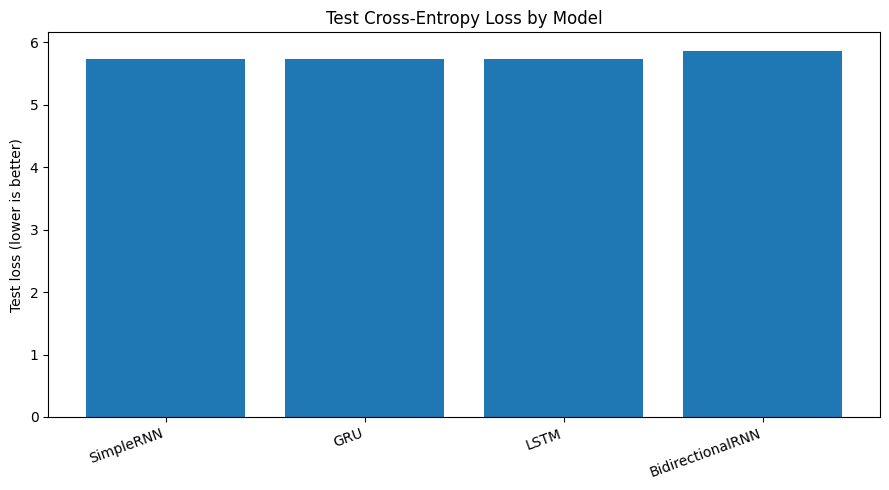

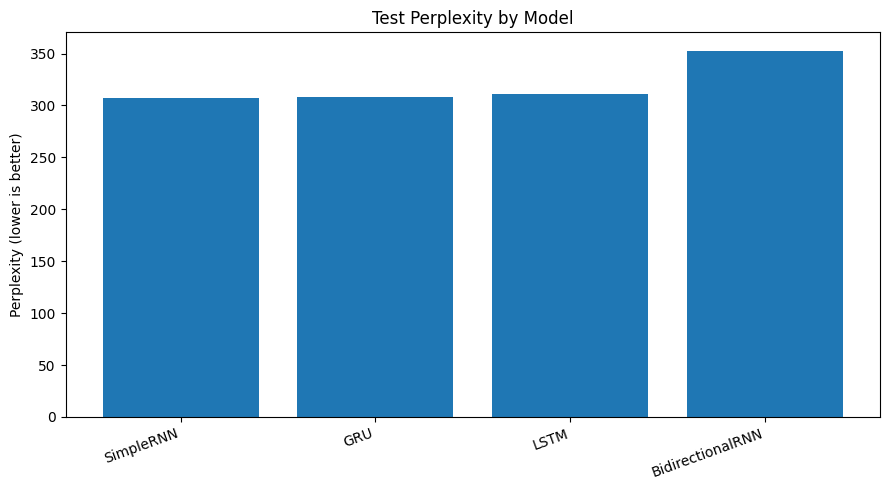

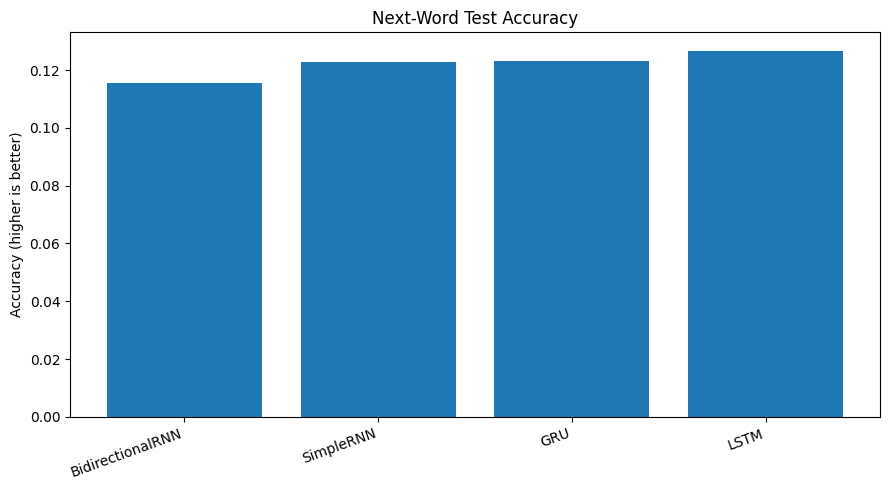

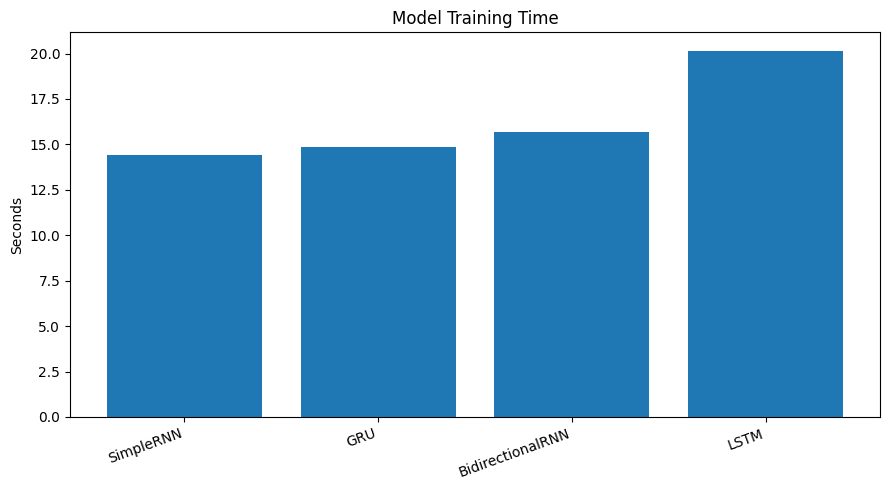

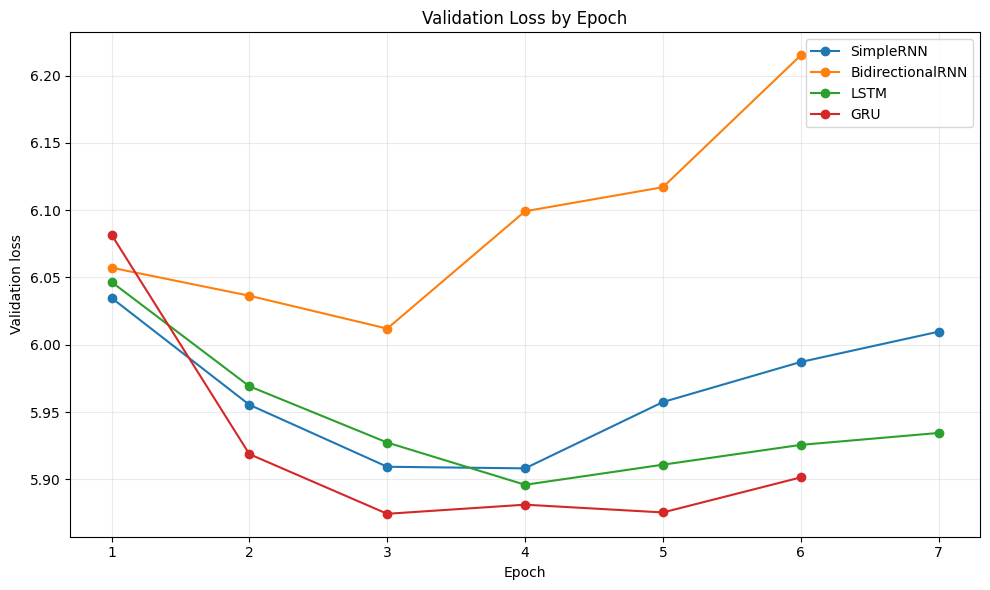

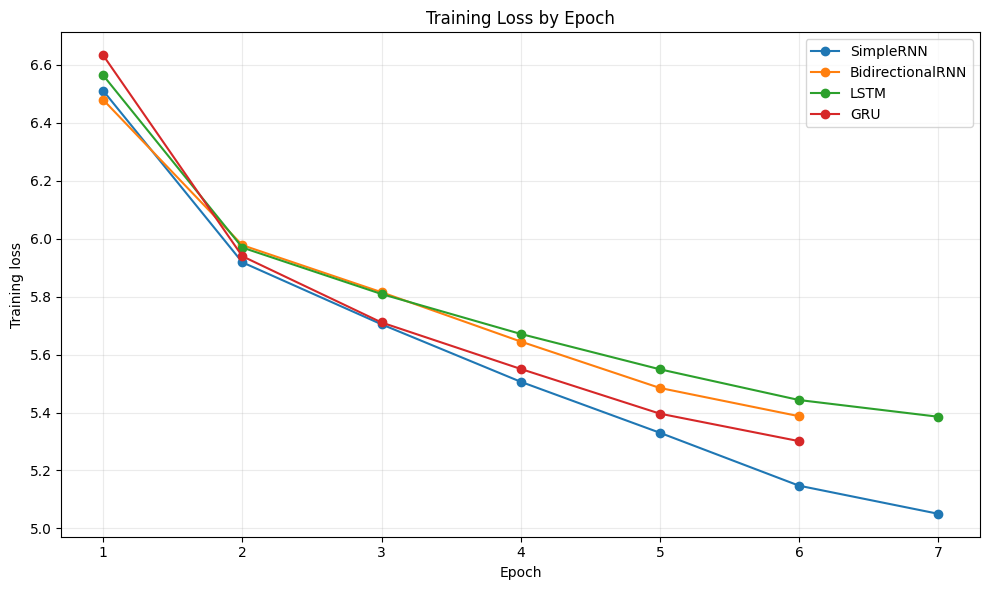

Charts saved in: /kaggle/working/fgai_results


In [6]:

# CELL 6 — Comparison charts and training curves

def save_bar_chart(column, title, ylabel, filename):
    ordered = results_df.sort_values(column, ascending=True)

    plt.figure(figsize=(9, 5))
    plt.bar(ordered["Model"], ordered[column])
    plt.title(title)
    plt.ylabel(ylabel)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()

save_bar_chart(
    "Test_Loss",
    "Test Cross-Entropy Loss by Model",
    "Test loss (lower is better)",
    "test_loss_comparison.png"
)

save_bar_chart(
    "Test_Perplexity",
    "Test Perplexity by Model",
    "Perplexity (lower is better)",
    "test_perplexity_comparison.png"
)

save_bar_chart(
    "Test_Accuracy",
    "Next-Word Test Accuracy",
    "Accuracy (higher is better)",
    "test_accuracy_comparison.png"
)

save_bar_chart(
    "Training_Time_Seconds",
    "Model Training Time",
    "Seconds",
    "training_time_comparison.png"
)

plt.figure(figsize=(10, 6))
for model_name, history in histories.items():
    plt.plot(
        range(1, len(history["val_loss"]) + 1),
        history["val_loss"],
        marker="o",
        label=model_name
    )

plt.title("Validation Loss by Epoch")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "validation_loss_curves.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

plt.figure(figsize=(10, 6))
for model_name, history in histories.items():
    plt.plot(
        range(1, len(history["loss"]) + 1),
        history["loss"],
        marker="o",
        label=model_name
    )

plt.title("Training Loss by Epoch")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "training_loss_curves.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

print("Charts saved in:", RESULTS_DIR)


In [7]:

# CELL 7 — Autoregressive generation and diversity metrics

TEMPERATURES = [0.5, 1.0, 1.5]
GENERATED_TOKENS = 60

SEED_TEXTS = [
    "to be or not to be that is the question",
    "wherefore art thou romeo",
    "all the world's a stage"
]

def encode_seed(text):
    seed_tokens = tokenize_text(text)
    ids = [word_to_id.get(w, UNK_ID) for w in seed_tokens]

    if not ids:
        raise ValueError(f"No usable tokens in seed: {text}")

    while len(ids) < CONTEXT_LEN:
        ids = ids + ids

    return ids[-CONTEXT_LEN:]


def detokenize(tokens):
    text = " ".join(tokens)
    # Attach punctuation to the preceding token.
    text = re.sub(r"\s+([,.;:!?%])", r"\1", text)
    text = re.sub(r"\s+(['’])", r"\1", text)
    text = re.sub(r"([(])\s+", r"\1", text)
    return text


def generate_text(model, seed, temperature, num_tokens=60):
    if temperature <= 0:
        raise ValueError("Temperature must be positive.")

    context = encode_seed(seed)
    generated = list(context)

    for _ in range(num_tokens):
        x = np.asarray(
            [generated[-CONTEXT_LEN:]], dtype=np.int32
        )

        probabilities = model.predict(x, verbose=0)[0]
        probabilities = np.asarray(
            probabilities, dtype=np.float64
        )

        probabilities = np.maximum(probabilities, 1e-12)
        logits = np.log(probabilities) / temperature

        # Do not sample reserved PAD or UNK tokens.
        logits[PAD_ID] = -np.inf
        logits[UNK_ID] = -np.inf

        logits -= np.max(logits)
        probs = np.exp(logits)
        probs /= probs.sum()

        next_id = int(np.random.choice(len(probs), p=probs))
        generated.append(next_id)

    new_tokens = [
        id_to_word.get(i, "<UNK>")
        for i in generated[len(context):]
    ]

    return detokenize(new_tokens)


def diversity_metrics(text):
    words = tokenize_text(text)

    def distinct_n(n):
        if len(words) < n:
            return 0.0

        ngrams = [
            tuple(words[i:i+n])
            for i in range(len(words) - n + 1)
        ]
        return len(set(ngrams)) / len(ngrams)

    repetition_ratio = (
        1.0 - len(set(words)) / len(words)
        if words else 0.0
    )

    return {
        "Token_Count": len(words),
        "Distinct_1": distinct_n(1),
        "Distinct_2": distinct_n(2),
        "Repetition_Ratio": repetition_ratio
    }


generation_rows = []
sample_number = 0

for model_name in MODEL_NAMES:
    model = models[model_name]

    for seed_text in SEED_TEXTS:
        for temperature in TEMPERATURES:
            sample_number += 1
            rng_seed = SEED + sample_number
            np.random.seed(rng_seed)
            random.seed(rng_seed)

            generated = generate_text(
                model=model,
                seed=seed_text,
                temperature=temperature,
                num_tokens=GENERATED_TOKENS
            )

            generation_rows.append({
                "Model": model_name,
                "Seed": seed_text,
                "Temperature": temperature,
                "Generated_Text": generated,
                "Sampling_Seed": rng_seed,
                **diversity_metrics(generated)
            })

            print("\n" + "=" * 80)
            print(f"Model: {model_name}")
            print(f"Seed: {seed_text}")
            print(f"Temperature: {temperature}")
            print(generated)

generation_df = pd.DataFrame(generation_rows)

generation_df.to_csv(
    RESULTS_DIR / "generated_samples.csv", index=False
)

with open(
    RESULTS_DIR / "generated_samples.txt",
    "w", encoding="utf-8"
) as f:
    for row in generation_rows:
        f.write(f"\nModel: {row['Model']}\n")
        f.write(f"Seed: {row['Seed']}\n")
        f.write(f"Temperature: {row['Temperature']}\n")
        f.write(f"Generated text: {row['Generated_Text']}\n")
        f.write(
            f"Distinct-1: {row['Distinct_1']:.3f}; "
            f"Distinct-2: {row['Distinct_2']:.3f}; "
            f"Repetition ratio: {row['Repetition_Ratio']:.3f}\n"
        )

assert len(generation_df) == 36
assert generation_df["Model"].nunique() == 4
assert generation_df["Seed"].nunique() == 3
assert generation_df["Temperature"].nunique() == 3

print("\nVerified generated samples:", len(generation_df))



Model: SimpleRNN
Seed: to be or not to be that is the question
Temperature: 0.5
, to the lord,' her is, for i will the be on, i, the fool of where the angry is of the next, and the king, my twere we! i, and give the horse. what, now, i find you, i, in i have not that my

Model: SimpleRNN
Seed: to be or not to be that is the question
Temperature: 1.0
good' offer, thou further which! now him over so be: i murderers re already with be needs in therefore kin, when said you hath not? i is be haply excused on it' i breath, sense this venice of fare caesar hard, their wind. a heathen and oberon the king in

Model: SimpleRNN
Seed: to be or not to be that is the question
Temperature: 1.5
glorify kind on the writ be in as him keep durst wish lesson tidings thing: untainted second rude he's seem to death by more met golden were cured here out. money when rank why they sickness with by jaques an overthrown than you relish meant i levy is but be clamours leave: what liars words all it

Model: Simp

,Model,Temperature,Distinct_1,Distinct_2,Repetition_Ratio
0,BidirectionalRNN,0.5,0.438889,0.881356,0.561111
1,BidirectionalRNN,1.0,0.761111,0.988701,0.238889
2,BidirectionalRNN,1.5,0.922222,1.000000,0.077778
3,GRU,0.5,0.455556,0.836158,0.544444
4,GRU,1.0,0.777778,1.000000,0.222222
5,GRU,1.5,0.944444,1.000000,0.055556
6,LSTM,0.5,0.383333,0.706215,0.616667
7,LSTM,1.0,0.766667,0.994350,0.233333
8,LSTM,1.5,0.922222,1.000000,0.077778
9,SimpleRNN,0.5,0.500000,0.853107,0.500000


,Temperature,Distinct_1,Distinct_2,Repetition_Ratio
0,0.5,0.444444,0.819209,0.555556
1,1.0,0.772222,0.995763,0.227778
2,1.5,0.930556,1.000000,0.069444


,Model,Distinct_1,Distinct_2,Repetition_Ratio
0,BidirectionalRNN,0.707407,0.956685,0.292593
1,GRU,0.725926,0.945386,0.274074
2,LSTM,0.690741,0.900188,0.309259
3,SimpleRNN,0.738889,0.951036,0.261111


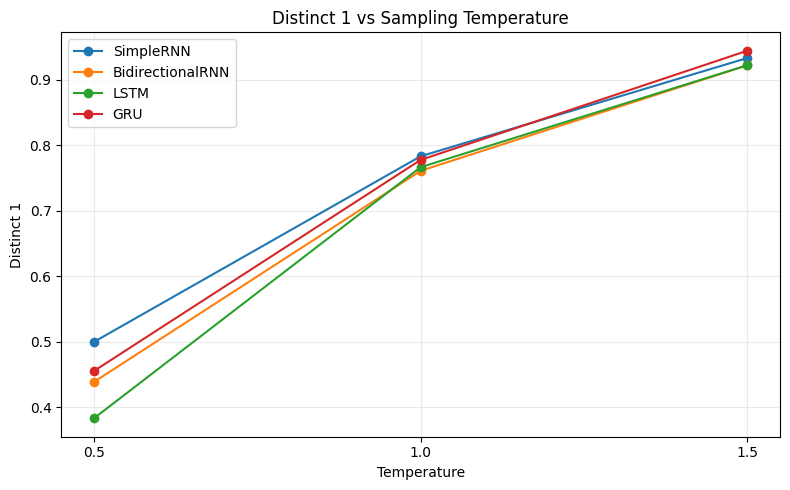

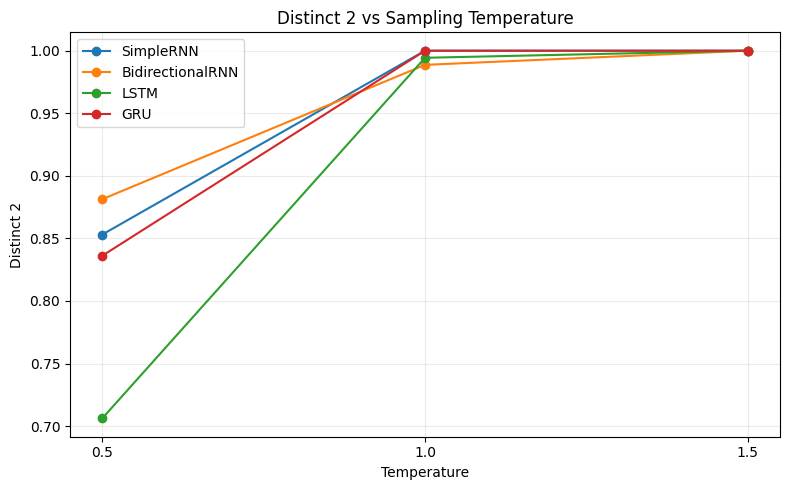

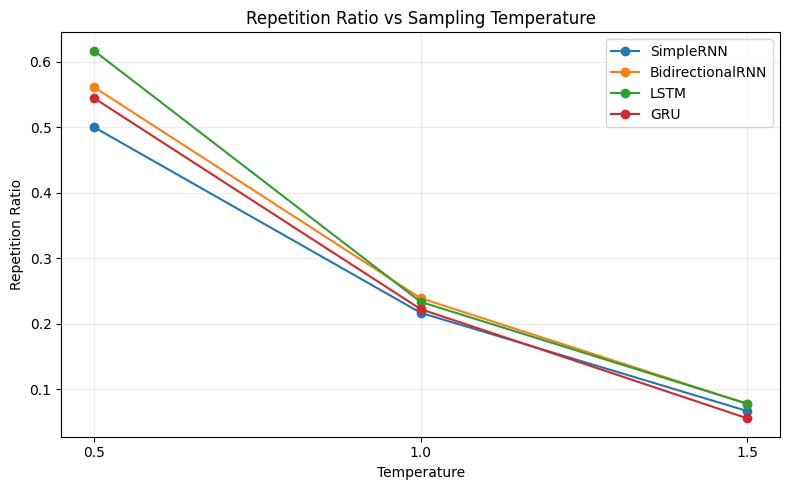

Reminder: greater lexical diversity is not automatically better coherence or contextual consistency.


In [8]:

# CELL 8 — Quantitative temperature analysis

model_temperature_summary = (
    generation_df.groupby(["Model", "Temperature"])[
        ["Distinct_1", "Distinct_2", "Repetition_Ratio"]
    ]
    .mean()
    .reset_index()
    .sort_values(["Model", "Temperature"])
)

temperature_summary = (
    generation_df.groupby("Temperature")[
        ["Distinct_1", "Distinct_2", "Repetition_Ratio"]
    ]
    .mean()
    .reset_index()
)

model_generation_summary = (
    generation_df.groupby("Model")[
        ["Distinct_1", "Distinct_2", "Repetition_Ratio"]
    ]
    .mean()
    .reset_index()
)

display(model_temperature_summary)
display(temperature_summary)
display(model_generation_summary)

model_temperature_summary.to_csv(
    RESULTS_DIR / "model_temperature_analysis.csv", index=False
)
temperature_summary.to_csv(
    RESULTS_DIR / "temperature_analysis.csv", index=False
)
model_generation_summary.to_csv(
    RESULTS_DIR / "model_generation_summary.csv", index=False
)

for metric in ["Distinct_1", "Distinct_2", "Repetition_Ratio"]:
    plt.figure(figsize=(8, 5))

    for model_name in MODEL_NAMES:
        subset = model_temperature_summary[
            model_temperature_summary["Model"] == model_name
        ]
        plt.plot(
            subset["Temperature"],
            subset[metric],
            marker="o",
            label=model_name
        )

    plt.title(f"{metric.replace('_', ' ')} vs Sampling Temperature")
    plt.xlabel("Temperature")
    plt.ylabel(metric.replace("_", " "))
    plt.xticks(TEMPERATURES)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(
        RESULTS_DIR / f"{metric.lower()}_temperature.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()

print(
    "Reminder: greater lexical diversity is not automatically "
    "better coherence or contextual consistency."
)


In [9]:

# CELL 9 — Human qualitative evaluation worksheet

qualitative_df = generation_df[
    ["Model", "Seed", "Temperature", "Generated_Text"]
].copy()

# Fill these scores after reading each generated passage.
# Use integers from 1 (poor) to 5 (strong).
qualitative_df["Coherence_Score_1_to_5"] = np.nan
qualitative_df["Contextual_Consistency_1_to_5"] = np.nan
qualitative_df["Readability_Score_1_to_5"] = np.nan
qualitative_df["Evaluator_Notes"] = ""

qualitative_df.to_csv(
    RESULTS_DIR / "qualitative_evaluation_worksheet.csv",
    index=False
)

print("Qualitative evaluation worksheet created.")
display(qualitative_df.head(10))

print("""
How to use:
1. Download qualitative_evaluation_worksheet.csv.
2. Read each generated passage in generated_samples.csv.
3. Enter scores from 1 (poor) to 5 (strong).
4. Add brief notes about repetition, grammar, coherence and relevance.
5. Upload the completed worksheet into the repository.
""")


Qualitative evaluation worksheet created.


,Model,Seed,Temperature,Generated_Text,Coherence_Score_1_to_5,Contextual_Consistency_1_to_5,Readability_Score_1_to_5,Evaluator_Notes
0,SimpleRNN,to be or not to be that is the question,0.5,", to the lord,' her is, for i will the be on, ...",NaN,NaN,NaN,
1,SimpleRNN,to be or not to be that is the question,1.0,"good' offer, thou further which! now him over ...",NaN,NaN,NaN,
2,SimpleRNN,to be or not to be that is the question,1.5,glorify kind on the writ be in as him keep dur...,NaN,NaN,NaN,
3,SimpleRNN,wherefore art thou romeo,0.5,". it, me, what, i am the heart, and your word,...",NaN,NaN,NaN,
4,SimpleRNN,wherefore art thou romeo,1.0,", modern iii to revenge that bring it gold, it...",NaN,NaN,NaN,
5,SimpleRNN,wherefore art thou romeo,1.5,", suffering not whose signal show pitied will ...",NaN,NaN,NaN,
6,SimpleRNN,all the world's a stage,0.5,". i am will not to a lord of do it, i will his...",NaN,NaN,NaN,
7,SimpleRNN,all the world's a stage,1.0,this thy leave to him helm. dear creature. but...,NaN,NaN,NaN,
8,SimpleRNN,all the world's a stage,1.5,"herself, our maintain part secrecy his win eff...",NaN,NaN,NaN,
9,BidirectionalRNN,to be or not to be that is the question,0.5,"., and my the man, will may is me, to i but i ...",NaN,NaN,NaN,



How to use:
1. Download qualitative_evaluation_worksheet.csv.
2. Read each generated passage in generated_samples.csv.
3. Enter scores from 1 (poor) to 5 (strong).
4. Add brief notes about repetition, grammar, coherence and relevance.
5. Upload the completed worksheet into the repository.



In [14]:

# CELL 10 — Experiment summary and README

best_idx = results_df["Validation_Loss"].idxmin()
best_model = str(results_df.loc[best_idx, "Model"])
best_row = results_df.loc[best_idx]

summary = {
    "assignment": "ICT4403 Foundations of Generative AI — Assignment 2",
    "project_title": (
        "Comparative Autoregressive Text Generation "
        "Using Simple RNN, Bidirectional RNN, LSTM and GRU"
    ),
    "dataset": dataset_info,
    "configuration": {
        "seed": SEED,
        "context_length": CONTEXT_LEN,
        "vocabulary_size": VOCAB_SIZE,
        "embedding_dimension": EMBED_DIM,
        "hidden_units": HIDDEN_UNITS,
        "batch_size": BATCH_SIZE,
        "maximum_epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "temperatures": TEMPERATURES,
        "generation_seed_prompts": SEED_TEXTS
    },
    "selection_metric": "Lowest validation loss",
    "selected_model": best_model,
    "selected_model_validation_loss": float(best_row["Validation_Loss"]),
    "selected_model_test_loss": float(best_row["Test_Loss"]),
    "model_results": results_df.to_dict(orient="records"),
    "temperature_summary": temperature_summary.to_dict(orient="records"),
    "sample_count": len(generation_df)
}

with open(
    RESULTS_DIR / "experiment_summary.json", "w", encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

readme = f"""# Comparative Autoregressive Text Generation Using RNNs

## 1. Problem Statement and Objective

The objective is to develop an autoregressive next-word text-generation
system and compare Simple RNN, Bidirectional RNN, LSTM and GRU models
under a consistent experimental setup.

## 2. Dataset

- **Name:** Shakespeare Plays
- **Source:** {DATASET_URL}
- **File used:** {csv_path.name}
- **Column used:** PlayerLine
- **Non-empty dialogue lines:** {len(lines):,}
- **Token count:** {n_tokens:,}

The text is tokenized at the word level. The vocabulary is built using
training text only. Data is split chronologically into 80% training,
10% validation and 10% test partitions. Sequence windows are constructed
inside each partition.

## 3. Models

- **Simple RNN:** A vanilla recurrent neural network.
- **Bidirectional RNN:** Processes the supplied context in forward and
  backward directions.
- **LSTM:** Uses gated memory to regulate information flow.
- **GRU:** Uses update and reset gates with a simpler gated architecture.

Each model receives a context of {CONTEXT_LEN} tokens and predicts the
next token. Models share the vocabulary, embedding size, hidden-unit
count, output layer, optimiser and training protocol. The Bidirectional
RNN has a different parameter count because it has two recurrent directions.

## 4. Experimental Configuration

- Random seed: {SEED}
- Vocabulary size: {VOCAB_SIZE}
- Context length: {CONTEXT_LEN}
- Embedding dimension: {EMBED_DIM}
- Hidden units: {HIDDEN_UNITS}
- Batch size: {BATCH_SIZE}
- Maximum epochs: {EPOCHS}
- Optimiser: Adam
- Initial learning rate: {LEARNING_RATE}
- Early stopping: validation loss, patience 3
- Temperature values: {TEMPERATURES}
- Generated tokens per sample: {GENERATED_TOKENS}
- Generation prompts: {SEED_TEXTS}

Early stopping and learning-rate reduction are based on validation loss.
The best validation-loss checkpoint is evaluated on the test partition.
The test partition is not used for model selection.

## 5. Quantitative Results

{results_df.to_string(index=False)}

Loss is sparse categorical cross-entropy. Perplexity is exp(loss);
lower loss and perplexity generally indicate better next-token
probability estimates. Accuracy is the fraction of examples whose
highest-probability prediction matches the target. Training time is
hardware- and runtime-dependent.

## 6. Model Selection

The selected model is **{best_model}**, based on the lowest validation
loss ({float(best_row['Validation_Loss']):.4f}). Its held-out test loss
is {float(best_row['Test_Loss']):.4f}, test accuracy is
{float(best_row['Test_Accuracy']):.4f}, and test perplexity is
{float(best_row['Test_Perplexity']):.2f}.

This selection criterion does not guarantee that the model is best for
every qualitative generation characteristic. The other models should
also be discussed using the quantitative comparison and generated samples.

## 7. Temperature Analysis

All four models generate text from the same three seed prompts at
temperatures {TEMPERATURES}, producing {len(generation_df)} samples.

See `generated_samples.csv`, `generated_samples.txt`,
`temperature_analysis.csv` and `model_temperature_analysis.csv`.

Lower temperature generally concentrates probability on more likely
tokens. Higher temperature generally increases sampling randomness.
Distinct-1 and Distinct-2 measure unique unigram and bigram proportions.
Repetition ratio measures 1 minus the unique-token fraction.
These metrics describe lexical variation, not semantic coherence.

## 8. Qualitative Evaluation

Inspect generated passages for coherence, contextual consistency,
readability and repetition. Use `qualitative_evaluation_worksheet.csv`
to record human ratings and observations. Qualitative conclusions must
be based on the actual generated passages and completed ratings; they
are not inferred from diversity metrics alone.

## 9. Limitations

This is a word-level model with a finite vocabulary and context window.
The Shakespeare corpus contains historical language and stage directions.
A Bidirectional RNN is included as required for comparison, but it is
not a conventional causal language-model architecture. It only processes
the supplied context and does not receive future target tokens.

The experiment uses a bounded sample of sequence windows and a maximum
epoch count. Results depend on the dataset version, hardware, random
seed and training configuration. Further tuning or multiple runs may
change the model ranking.

## 10. Reproducibility

1. Open the notebook in Kaggle.
2. Attach the Shakespeare Plays dataset.
3. Select a GPU accelerator if available.
4. Run all notebook cells in order.
5. Review the generated samples and qualitative worksheet.

Dependencies: Python, TensorFlow, NumPy, pandas and Matplotlib.

## 11. Files

- `model_comparison.csv`: quantitative model metrics
- `*_training_history.csv`: per-epoch training and validation metrics
- `generated_samples.csv` and `.txt`: generated passages
- `temperature_analysis.csv`: mean generation metrics by temperature
- `model_temperature_analysis.csv`: generation metrics by model and temperature
- `qualitative_evaluation_worksheet.csv`: human evaluation template
- PNG files: comparison and temperature plots
- `experiment_summary.json`: experiment configuration and results

Dataset attribution and licence terms should be checked before redistribution.
"""

(RESULTS_DIR / "README.md").write_text(readme, encoding="utf-8")

print("Selected model by validation loss:", best_model)
print("\nSummary saved:", RESULTS_DIR / "experiment_summary.json")
print("README saved:", RESULTS_DIR / "README.md")
display(results_df)


Selected model by validation loss: GRU

Summary saved: /kaggle/working/fgai_results/experiment_summary.json
README saved: /kaggle/working/fgai_results/README.md


,Model,Parameters,Best_Epoch,Epochs_Trained,Training_Time_Seconds,Validation_Loss,Validation_Accuracy,Validation_Perplexity,Test_Loss,Test_Accuracy,Test_Perplexity
0,GRU,1989072,3,6,14.84,5.874403,0.1288,355.812177,5.729193,0.1230,307.720756
1,LSTM,2004240,4,7,20.16,5.895957,0.1304,363.564598,5.739556,0.1267,310.926426
2,SimpleRNN,1957872,4,7,14.40,5.908167,0.1273,368.031069,5.728740,0.1228,307.581538
3,BidirectionalRNN,1985616,3,6,15.70,6.011996,0.1245,408.297579,5.865927,0.1156,352.809136


In [15]:

# CELL 11 — Export results bundle

bundle_path = OUTPUT_DIR / "fgai_assignment2_results.zip"

with zipfile.ZipFile(
    bundle_path, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in sorted(RESULTS_DIR.rglob("*")):
        if path.is_file():
            zf.write(
                path,
                arcname=f"fgai_results/{path.relative_to(RESULTS_DIR)}"
            )

print("Results folder:", RESULTS_DIR)
print("Models folder:", MODELS_DIR)
print("ZIP bundle:", bundle_path)
print("ZIP size (MB):", round(bundle_path.stat().st_size / (1024**2), 2))

print("\nExported files:")
for path in sorted(RESULTS_DIR.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(RESULTS_DIR)} "
              f"({path.stat().st_size / 1024:.1f} KB)")


Results folder: /kaggle/working/fgai_results
Models folder: /kaggle/working/fgai_models
ZIP bundle: /kaggle/working/fgai_assignment2_results.zip
ZIP size (MB): 0.71

Exported files:
BidirectionalRNN_training_history.csv (0.6 KB)
GRU_training_history.csv (0.6 KB)
LSTM_training_history.csv (0.7 KB)
README.md (6.0 KB)
SimpleRNN_training_history.csv (0.7 KB)
distinct_1_temperature.png (105.1 KB)
distinct_2_temperature.png (90.4 KB)
experiment_summary.json (3.6 KB)
generated_samples.csv (12.2 KB)
generated_samples.txt (14.1 KB)
metadata.json (0.5 KB)
model_comparison.csv (0.7 KB)
model_generation_summary.csv (0.3 KB)
model_temperature_analysis.csv (0.8 KB)
qualitative_evaluation_worksheet.csv (10.8 KB)
repetition_ratio_temperature.png (112.8 KB)
temperature_analysis.csv (0.2 KB)
test_accuracy_comparison.png (57.5 KB)
test_loss_comparison.png (51.5 KB)
test_perplexity_comparison.png (56.4 KB)
training_loss_curves.png (125.6 KB)
training_time_comparison.png (47.5 KB)
validation_loss_curves.pn

In [16]:

# CELL 12 — Final validation of the assignment outputs

required_files = [
    "metadata.json",
    "vocabulary.json",
    "model_comparison.csv",
    "temperature_analysis.csv",
    "model_temperature_analysis.csv",
    "model_generation_summary.csv",
    "generated_samples.csv",
    "generated_samples.txt",
    "qualitative_evaluation_worksheet.csv",
    "experiment_summary.json",
    "README.md",
    "test_loss_comparison.png",
    "test_perplexity_comparison.png",
    "test_accuracy_comparison.png",
    "training_time_comparison.png",
    "validation_loss_curves.png",
    "training_loss_curves.png"
]

missing = [
    name for name in required_files
    if not (RESULTS_DIR / name).exists()
]

for name in required_files:
    print(f"{'OK' if (RESULTS_DIR / name).exists() else 'MISSING'}: {name}")

final_comparison = pd.read_csv(
    RESULTS_DIR / "model_comparison.csv"
)
final_samples = pd.read_csv(
    RESULTS_DIR / "generated_samples.csv"
)

print("\nModel count:", final_comparison["Model"].nunique())
print("Sample count:", len(final_samples))
print("Prompt count:", final_samples["Seed"].nunique())
print("Temperature count:", final_samples["Temperature"].nunique())

assert not missing, f"Missing required files: {missing}"
assert final_comparison["Model"].nunique() == 4
assert len(final_samples) == 36
assert final_samples["Seed"].nunique() == 3
assert final_samples["Temperature"].nunique() == 3
assert set(final_samples["Model"]) == set(MODEL_NAMES)
assert set(final_samples["Temperature"]) == set(TEMPERATURES)
assert bundle_path.exists()

print("\nAll automated output checks passed.")
print("Selected model:", best_model)
print("Remember to complete the qualitative worksheet manually.")


OK: metadata.json
OK: vocabulary.json
OK: model_comparison.csv
OK: temperature_analysis.csv
OK: model_temperature_analysis.csv
OK: model_generation_summary.csv
OK: generated_samples.csv
OK: generated_samples.txt
OK: qualitative_evaluation_worksheet.csv
OK: experiment_summary.json
OK: README.md
OK: test_loss_comparison.png
OK: test_perplexity_comparison.png
OK: test_accuracy_comparison.png
OK: training_time_comparison.png
OK: validation_loss_curves.png
OK: training_loss_curves.png

Model count: 4
Sample count: 36
Prompt count: 3
Temperature count: 3

All automated output checks passed.
Selected model: GRU
Remember to complete the qualitative worksheet manually.



# Results and Discussion

## 1. Quantitative Comparison

Four recurrent neural architectures were compared using validation
loss, test loss, perplexity, next-word accuracy and training time.

The GRU achieved the lowest validation loss of 5.8744 and was selected
as the preferred model using the validation set. Its test loss was
5.7292, with a test accuracy of 12.30% and test perplexity of 307.72.

The Simple RNN achieved the lowest test loss of 5.7287 and test
perplexity of 307.58, while the LSTM achieved the highest test accuracy
of 12.67%. The GRU and Simple RNN had very similar test losses.
The Bidirectional RNN recorded the highest test loss of 5.8659 and
the lowest test accuracy of 11.56%.

These results show that no single model achieved the best value
for every metric. Model selection was based on validation loss,
while test metrics were reserved for final evaluation.

## 2. Influence of Sampling Temperature

All four models generated text from three seed prompts at temperatures
0.5, 1.0 and 1.5, producing 36 generated samples.

Across all models, the mean Distinct-1 score increased from 0.444
at temperature 0.5 to 0.772 at temperature 1.0 and 0.931 at
temperature 1.5. The mean repetition ratio decreased from 0.556
to 0.228 and 0.069, respectively.

Mean Distinct-2 increased from 0.819 at temperature 0.5 to 0.996
at temperature 1.0 and 1.000 at temperature 1.5.

These results indicate that higher temperatures produced more
lexically varied text with fewer repeated tokens. However, higher
lexical diversity does not necessarily indicate better grammar,
coherence or contextual consistency.

## 3. Qualitative Evaluation

Inspection of the generated passages showed that the models could
produce Shakespeare-like vocabulary and occasional plausible phrases.
However, many passages also contained grammatical inconsistencies,
unrelated words and character names, and weak continuation of the
initial prompt.

At lower temperature, some passages repeated common function words
and short patterns. At higher temperature, vocabulary became more
varied, but the resulting text was not consistently coherent.

The generated passages therefore demonstrate the difference between
lexical diversity and meaningful text generation. Distinct-1,
Distinct-2 and repetition ratio are useful quantitative indicators,
but they do not directly measure semantic coherence or readability.

## 4. Model Selection and Limitations

The GRU was selected using the lowest validation loss of 5.8744.
The Simple RNN performed marginally better on test loss, and the
LSTM achieved the highest test accuracy. These differences indicate
that the model ranking depends on the evaluation metric.

The experiment is limited by word-level tokenisation, a finite
vocabulary, a fixed context window and a bounded training sample.
The models were trained for a maximum of ten epochs, with early
stopping based on validation loss. Results may vary with the random
seed, training configuration and dataset split.

The Bidirectional RNN is included as a comparison architecture.
It processes the supplied context in both directions but does not
receive future target tokens.

## 5. Conclusion

This experiment implemented and compared Simple RNN, Bidirectional
RNN, LSTM and GRU models for next-word prediction and autoregressive
text generation using the Shakespeare Plays dataset.

The GRU was selected based on validation loss, although the Simple
RNN achieved marginally lower test loss and the LSTM achieved the
highest test accuracy. Temperature experiments showed that higher
sampling temperatures increased lexical diversity and reduced
repetition, while qualitative inspection revealed limitations in
coherence and contextual consistency.

The results demonstrate that predictive metrics and generation
quality must be considered together when comparing neural
text-generation architectures.


In [18]:
import os
p = "/kaggle/working/fgai_assignment2_results.zip"
print("Found:", os.path.exists(p))
if os.path.exists(p):
    print("Size:", round(os.path.getsize(p) / 1024 / 1024, 2), "MB")

Found: True
Size: 0.71 MB
